<a href="https://colab.research.google.com/github/2025ciayushraj/DAV-/blob/main/k_means_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
data.target[[10, 50, 85]]
list(data.target_names)

[np.str_('malignant'), np.str_('benign')]

First 5 rows of Dataset:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst 

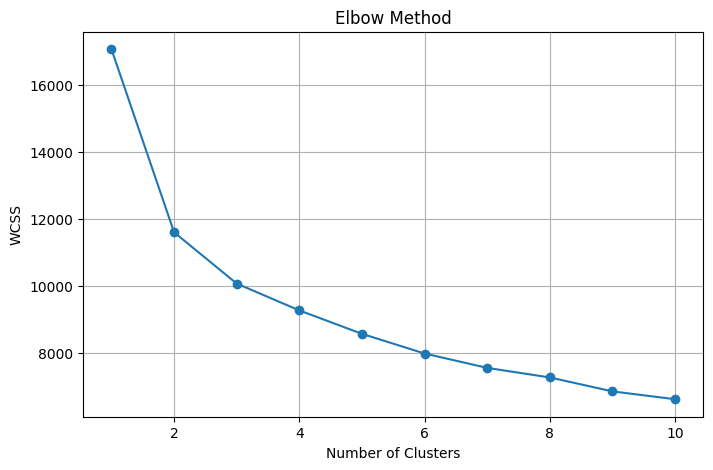


Clustered Dataset:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   
5        12.45         15.70           82.57      477.1          0.12780   
6        18.25         19.98          119.60     1040.0          0.09463   
7        13.71         20.83           90.20      577.9          0.11890   
8        13.00         21.82           87.50      519.8          0.12730   
9        12.46         24.04           83.97      475.9          0.11860   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760         0.30010              0.14710         0.2

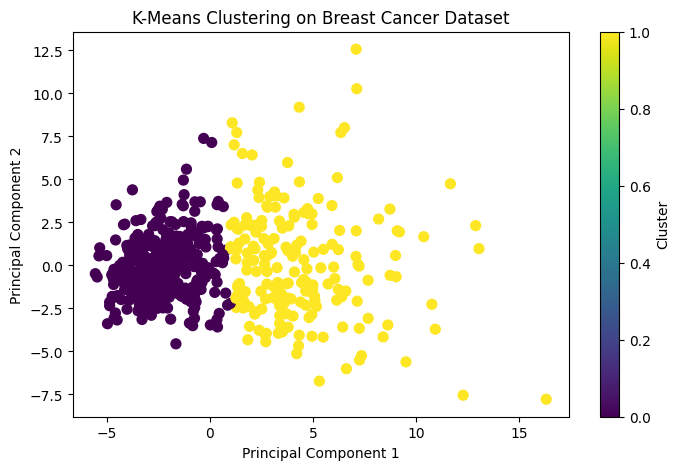


Silhouette Score: 0.34338224069077816

Cluster Distribution:
Cluster
0    375
1    194
Name: count, dtype: int64

Cluster Centers:
[[-0.48299485 -0.23904142 -0.50041892 -0.47814154 -0.3110035  -0.52601873
  -0.57903569 -0.58717117 -0.30908386 -0.1491409  -0.42798514 -0.02110994
  -0.43097168 -0.40175149 -0.02383127 -0.37020054 -0.3345976  -0.39771232
  -0.07493017 -0.23682231 -0.51785387 -0.25147802 -0.53231144 -0.49935772
  -0.31607814 -0.49224121 -0.53684332 -0.58010099 -0.30335497 -0.33672889]
 [ 0.93362406  0.4620646   0.96730462  0.92424266  0.60116657  1.01678879
   1.11927003  1.13499581  0.59745592  0.28828783  0.82729086  0.0408053
   0.83306382  0.77658149  0.0460656   0.71559384  0.64677371  0.76877382
   0.14483925  0.45777508  1.00100618  0.48610441  1.02895252  0.96525332
   0.61097579  0.95149718  1.0377126   1.12132923  0.58638203  0.65089347]]

Adjusted Rand Index:
0.6536246043910179

Final Dataset:
     mean radius  mean texture  mean perimeter  mean area  mean smoot

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

cancer = load_breast_cancer()

df = pd.DataFrame(cancer.data, columns=cancer.feature_names)

print("First 5 rows of Dataset:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

scaler = StandardScaler()
X = scaler.fit_transform(df)

print("\nData Preprocessing Completed!")

wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.grid()
plt.show()

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

y_kmeans = kmeans.fit_predict(X)

df['Cluster'] = y_kmeans

print("\nClustered Dataset:")
print(df.head(10))

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y_kmeans,
    cmap='viridis',
    s=50
)

plt.title("K-Means Clustering on Breast Cancer Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

score = silhouette_score(X, y_kmeans)

print("\nSilhouette Score:", score)

print("\nCluster Distribution:")
print(df['Cluster'].value_counts())

print("\nCluster Centers:")
print(kmeans.cluster_centers_)

print("\nAdjusted Rand Index:")
print(adjusted_rand_score(cancer.target, y_kmeans))


print("\nFinal Dataset:")
print(df)

print("\nK-Means Clustering Completed Successfully!")